In [130]:
##### PS_1
### 1.1
# 加载pandas和plot
import pandas as pd
import matplotlib.pyplot as plt

# 读取文件
Sig_Eqs = pd.read_csv("..\ESE5023\earthquakes-2026-10-14_20-33-44_+0800.tsv",delimiter='\t').fillna(0)

# 将数据中数值的空值替换为0
num_cols = Sig_Eqs.select_dtypes(include='number').columns
Sig_Eqs[num_cols] = Sig_Eqs[num_cols].fillna(0)

# 统计死亡人数
Deaths_Country = Sig_Eqs.groupby('Country')['Total Deaths'].sum().reset_index().sort_values(by='Total Deaths',ascending=False).reset_index(drop=True)
print(Deaths_Country.head(20))

         Country  Total Deaths
0          CHINA     2106526.0
1         TURKEY     1008867.0
2           IRAN      761656.0
3          SYRIA      488326.0
4          ITALY      417297.0
5          HAITI      323782.0
6          JAPAN      319510.0
7     AZERBAIJAN      319251.0
8      INDONESIA      283485.0
9        ARMENIA      175000.0
10      PAKISTAN      143714.0
11       ECUADOR      134445.0
12  TURKMENISTAN      110412.0
13          PERU       97009.0
14        GREECE       83658.0
15      PORTUGAL       82572.0
16          IRAQ       70200.0
17         CHILE       70175.0
18         INDIA       63413.0
19        ISRAEL       58368.0


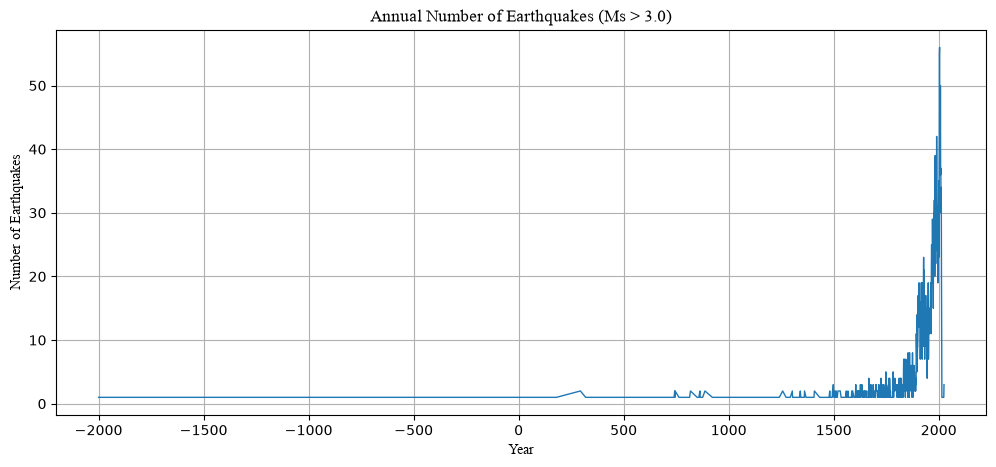

<Figure size 640x480 with 0 Axes>

In [131]:
### 1.2
# 筛选Ms > 3.0的时间
Ms_3 = Sig_Eqs.loc[(Sig_Eqs['Ms'] > 3.0)].reset_index(drop=True)

# 按年份统计次数
Ms_Year = Ms_3.groupby('Year').size()

# 绘图
plt.figure(figsize=(12,5))
plt.plot(Ms_Year,linewidth=1)
plt.xlabel('Year',fontname = 'Times New Roman')
plt.ylabel('Number of Earthquakes',fontname = 'Times New Roman')
plt.title('Annual Number of Earthquakes (Ms > 3.0)',fontname = 'Times New Roman')
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_1_2.png",
            dpi = 300,
            bbox_inches="tight")

In [150]:
### 1.3
# 定义函数CountEq_LargestEq()
def CountEq_LargestEq(country):
    # 读取输入的国家名称
    country_eq = Sig_Eqs[Sig_Eqs['Country'] == country]
    # 统计地震数量、date和location
    N = len(country_eq)
    ID = country_eq.loc[country_eq['Ms'].idxmax()]
    YY = int(ID['Year'])
    MM = int(ID['Mo'])
    DD = int(ID['Dy'])
    Loc = ID['Location Name']
    Lat = float(ID['Latitude'])
    Lon = float(ID['Longitude'])
    return N,YY,MM,DD,Loc,Lat,Lon

# 创建国家列表，排除NaN值和重复值
countries = Sig_Eqs['Country'].dropna().unique()

# 实际应用时发现有一国家名称为0，故舍去
countries = Sig_Eqs.loc[Sig_Eqs['Country'].notna()&(Sig_Eqs['Country'].astype(str) != '0'),'Country'].unique()

# 创建空列表以便储存结果
Res = []

# 循环读取各个国家的数据
for country in countries:
    res = CountEq_LargestEq(country)
    Res.append((country,*res))
    # 打印结果
    print(country,' has recorded a total number of ',res[0],'earthquakes since 2150 B.C. The largest event in the dataset occurred on ',res[2],'/',res[3],'/',res[1],'. \nThe affected area is listed as ',res[4],', with coordinates of ',res[5],'° lagitude and ',res[6],'° longitude.',sep='')

# 新建表头
columns = ['Country','N','YY','MM','DD','Loc','Lat','Lon',]
RES = pd.DataFrame(Res, columns=columns).sort_values(by='N',ascending=False).reset_index()
print(RES)

     index         Country    N    YY  MM  DD  \
0       14           CHINA  626  1920  12  16   
1       33           JAPAN  429   869   7  13   
2       73       INDONESIA  427  2004  12  26   
3        7            IRAN  385   856  12  22   
4        9          TURKEY  359  1939  12  26   
..     ...             ...  ...   ...  ..  ..   
157    154         BURUNDI    1  2004   2  24   
158    158  CZECH REPUBLIC    1  2008  11  22   
159    159      MADAGASCAR    1  2017   1  11   
160    160          ZAMBIA    1  2017   2  24   
161    161         COMOROS    1  2018   5  15   

                                             Loc     Lat      Lon  
0        CHINA:  GANSU PROVINCE, SHANXI PROVINCE  36.601  105.317  
1                                JAPAN:  SANRIKU  38.500  143.800  
2    INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST   3.295   95.982  
3                          IRAN:  DAMGHAN, QUMIS  36.200   54.300  
4                              TURKEY:  ERZINCAN  39.907   39.586  
.. 

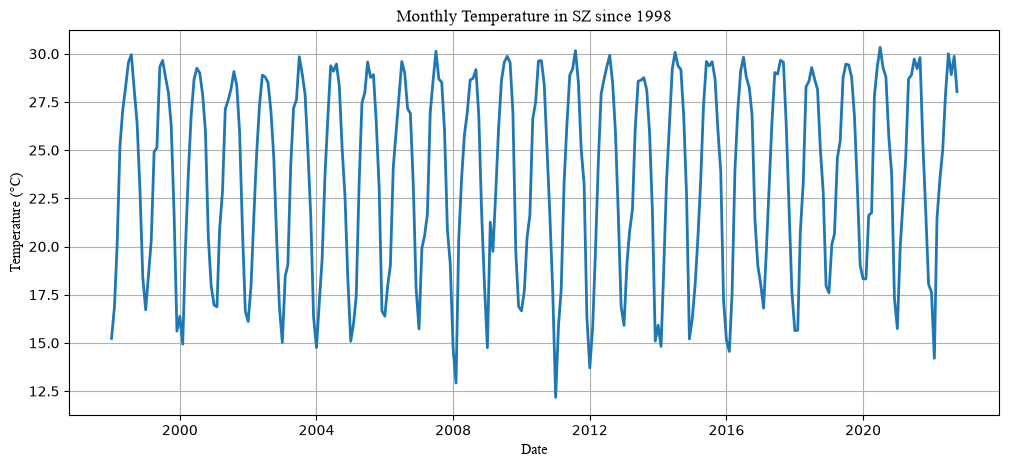

<Figure size 640x480 with 0 Axes>

In [151]:
##### PS_2
# 加载pandas和plot
import pandas as pd
import matplotlib.pyplot as plt

# 读取文件
data = pd.read_csv(r"..\ESE5023\Baoan_Weather_1998_2022.csv",low_memory=False)

# 转换日期格式
data['DATE'] = pd.to_datetime(data['DATE'])

# 命名表头
column = ['value', 'code']

# 拆分文件中的value和code再合并时间和表头
TMP = data['TMP'].str.split(',', expand=True)
TMP.columns = column
TMP.insert(0, 'DATE', data['DATE'])

# 将数据从str转换为float
TMP['value'] = pd.to_numeric(TMP['value'], errors='coerce')

# 筛选数据
TMP_true = TMP.loc[((TMP['code'] == '1') | (TMP['code'] == '5') | (TMP['code'] == '2') | (TMP['code'] == '4'))].reset_index(drop=True)
TMP_true = TMP_true.loc[((TMP_true['value'] > -932) & (TMP_true['value'] < 618))].reset_index(drop=True)

# 计算真值和逐月平均值
TMP_true['value'] = TMP_true['value'] / 10
TMP_mean = TMP_true.groupby(TMP_true['DATE'].dt.to_period('M'))['value'].mean()

# 绘图
plt.figure(figsize=(12, 5))
plt.plot(TMP_mean.index.to_timestamp(),TMP_mean.values,linewidth=2)
plt.xlabel('Date',fontname='Times New Roman')
plt.ylabel('Temperature (°C)',fontname='Times New Roman')
plt.title('Monthly Temperature in SZ since 1998',fontname='Times New Roman')
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_1_2.png",
            dpi = 300,
            bbox_inches="tight")

In [154]:
##### PS_3
# 加载pandas和plot
import pandas as pd
import matplotlib.pyplot as plt

### 3.1
# 读取文件
data3 = pd.read_csv(r"..\ESE5023\ibtracs.ALL.list.v04r00.csv",low_memory=False,usecols=range(17),skiprows=[1, 2],parse_dates=['ISO_TIME'],na_values=['NOT_NAMED', 'NAME'])
# 按SID分组并提取每个SID最大的风速
data3_1 = data3.groupby('SID').agg({'NAME': 'first', 'WMO_WIND': 'max'}).reset_index()

# 剔除NaN值
data3_1 = data3_1.loc[data3_1['NAME'].notna()]

# 按大小排序
data3_1 = data3_1.sort_values(by='WMO_WIND', ascending=False).head(10).reset_index(drop=True)
print(data3_1['NAME'].to_string(index=False))

   ABLE
CHARLIE
   EASY
    FOX
 GEORGE
CHARLIE
   EASY
    FOX
  BAKER
CHARLIE


In [341]:
### 3.2
# 按风速排序
data3_2 = data3.sort_values(by='WMO_WIND',ascending=False).head(20).reset_index(drop=True)

# 输出结果
for i in range(20): 
    print(i+1,'. ',data3_2['WMO_WIND'][i],'m/s',sep='')

1. 95m/s
2. 95m/s
3. 95m/s
4. 95m/s
5. 95m/s
6. 95m/s
7. 95m/s
8. 95m/s
9. 95m/s
10. 95m/s
11. 95m/s
12. 95m/s
13. 95m/s
14. 95m/s
15. 95m/s
16. 95m/s
17. 95m/s
18. 95m/s
19. 95m/s
20. 95m/s


In [342]:
### 3.3
print(data3.groupby(data3['BASIN']).size())

BASIN
EP     62412
NI     55401
SA       119
SI    160668
SP     67119
WP    236576
dtype: int64


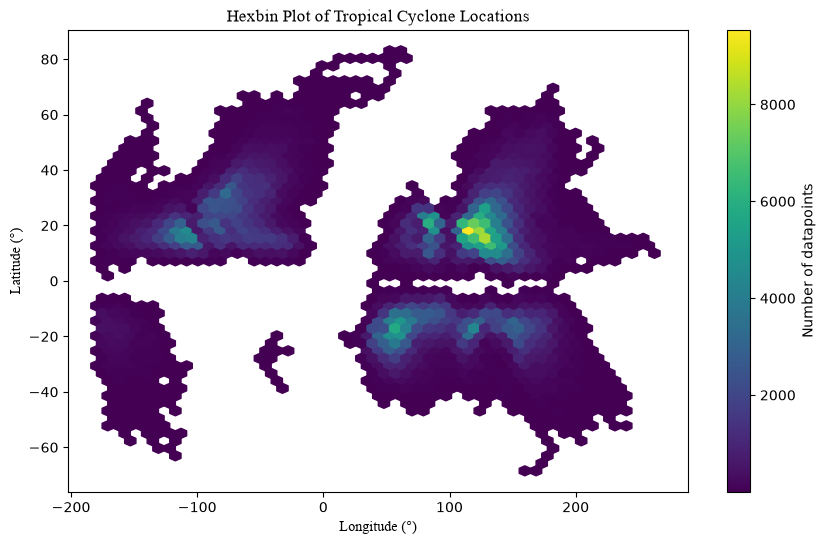

<Figure size 640x480 with 0 Axes>

In [96]:
### 3.4
# 读取经纬度并舍弃NaN值
data3_4 = data3.dropna(subset=['LAT', 'LON'])

# 绘图
plt.figure(figsize=(10, 6))
plt.hexbin(data3_4['LON'],data3_4['LAT'],gridsize=50,mincnt=1)
plt.colorbar(label='Number of datapoints')
plt.xlabel('Longitude (°)',fontname='Times New Roman')
plt.ylabel('Latitude (°)',fontname='Times New Roman')
plt.title('Hexbin Plot of Tropical Cyclone Locations',fontname='Times New Roman')
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_3_4.png",
            dpi = 300,
            bbox_inches="tight")

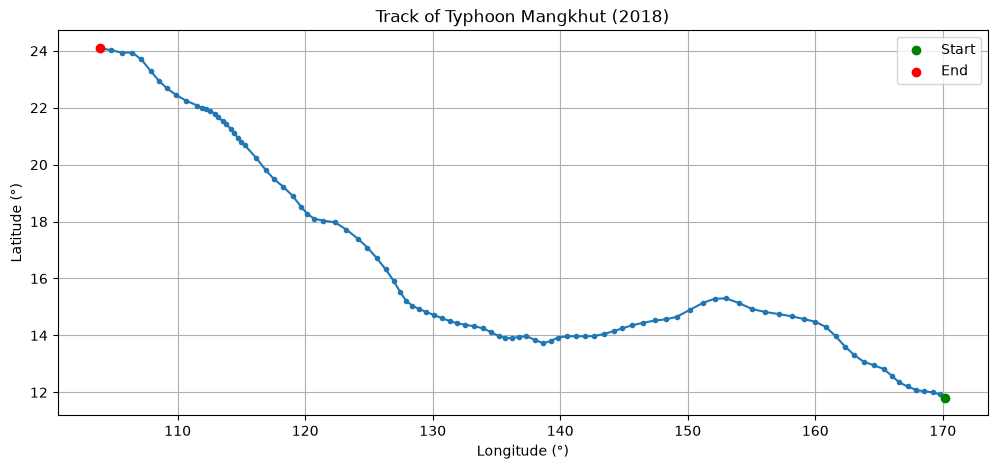

<Figure size 640x480 with 0 Axes>

In [97]:
### 3.5
# 获取2018年MANGKHUB数据
MANGKHUT = data3.loc[(data3['SEASON'] == 2018) &(data3['NAME'] == 'MANGKHUT')]

# 读取SID
sid = MANGKHUT['SID'].iloc[0]

# 提取该 SID 的所有记录
mangkhut = data3.loc[data3['SID'] == sid].copy()

# 剔除NaN值
mangkhut = mangkhut.dropna(subset=['LAT', 'LON'])

# 按时间排序
mangkhut = mangkhut.sort_values(by='ISO_TIME')

# 绘图
plt.figure(figsize=(12, 5))
plt.plot(mangkhut['LON'],mangkhut['LAT'],marker='o',markersize=3,linewidth=1.5)
plt.xlabel('Longitude (°)')
plt.ylabel('Latitude (°)')
plt.title('Track of Typhoon Mangkhut (2018)')
# 标记start & end位置
plt.scatter(mangkhut['LON'].iloc[0],mangkhut['LAT'].iloc[0],color='green',label='Start',zorder=3)
plt.scatter(mangkhut['LON'].iloc[-1], mangkhut['LAT'].iloc[-1],color='red',label='End',zorder=3)
plt.legend()
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_3_5.png",
            dpi = 300,
            bbox_inches="tight")

In [98]:
### 3.6
# 筛选1970年及之后的WP和EP的数据
data3_filtered = data3.loc[(data3['SEASON'] >= 1970) & ((data3['BASIN'] == 'EP') | (data3['BASIN'] == 'WP')) ].copy().reset_index(drop=True)

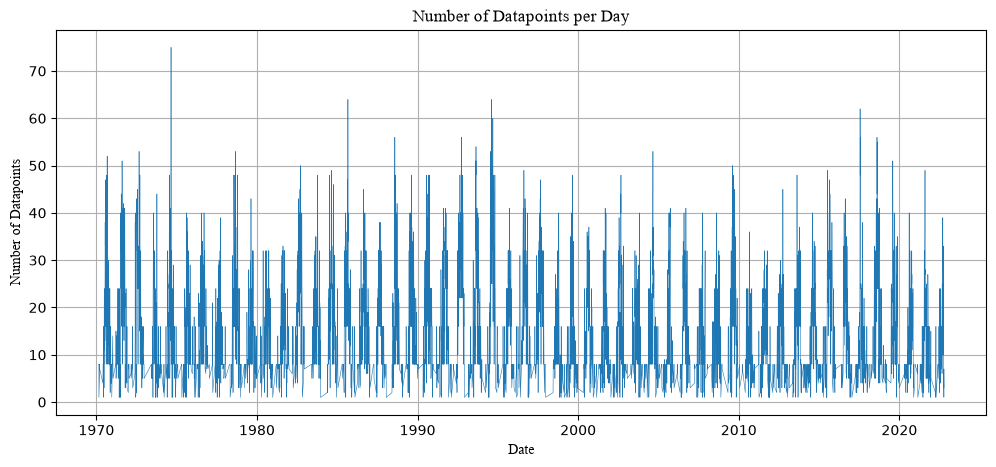

<Figure size 640x480 with 0 Axes>

In [121]:
### 3.7
# 提取日期
data3_filtered['DATE'] = data3_filtered['ISO_TIME'].dt.normalize()

# 统计点数
daily_n = data3_filtered.groupby('DATE').size()

# 绘图
plt.figure(figsize=(12, 5))
plt.plot(daily_n.index,daily_n.values,linewidth=0.4)
plt.xlabel('Date',fontname='Times New Roman')
plt.ylabel('Number of Datapoints',fontname='Times New Roman')
plt.title('Number of Datapoints per Day',fontname='Times New Roman')
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_3_7.png",
            dpi = 300,
            bbox_inches="tight")

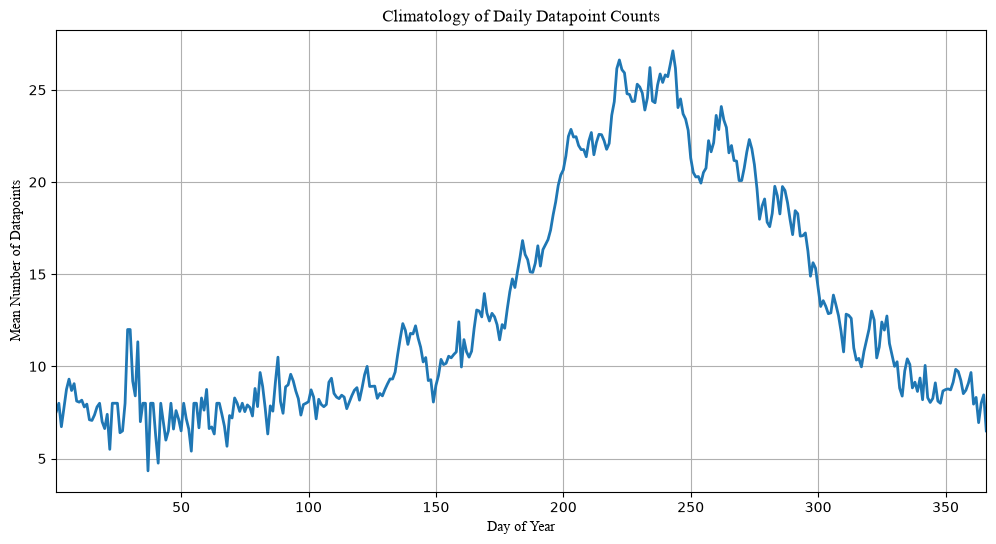

<Figure size 640x480 with 0 Axes>

In [118]:
### 3.8
# 重命名表头
daily_n_DoY = daily_n.rename('COUNT').reset_index()

# 使用dayofyear函数
daily_n_DoY['DAY_OF_YEAR'] = daily_n_DoY['DATE'].dt.dayofyear

# 计算平均值
climatology = daily_n_DoY.groupby('DAY_OF_YEAR')['COUNT'].mean()

# 绘图
plt.figure(figsize=(12, 6))
plt.plot(climatology.index,climatology.values,linewidth=2)
plt.xlabel('Day of Year',fontname='Times New Roman')
plt.ylabel('Mean Number of Datapoints',fontname='Times New Roman')
plt.title('Climatology of Daily Datapoint Counts',fontname='Times New Roman')
plt.xlim(1, 366)
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_3_8.png",
            dpi = 300,
            bbox_inches="tight")

In [47]:
### 3.9
# 匹配数据
daily_n_DoY['CLIMATOLOGY'] = daily_n_DoY['DAY_OF_YEAR'].map(climatology)

# 计算异常值
daily_n_DoY['ANOMALY'] = (daily_n_DoY['COUNT'] - daily_n_DoY['CLIMATOLOGY'])

# 输出结果
print(daily_n_DoY['ANOMALY'])

0         1.500000
1         0.000000
2         0.833333
3         1.400000
4         2.600000
           ...    
10812    -8.980769
10813   -11.693878
10814   -17.301887
10815   -12.769231
10816   -15.269231
Name: ANOMALY, Length: 10817, dtype: float64


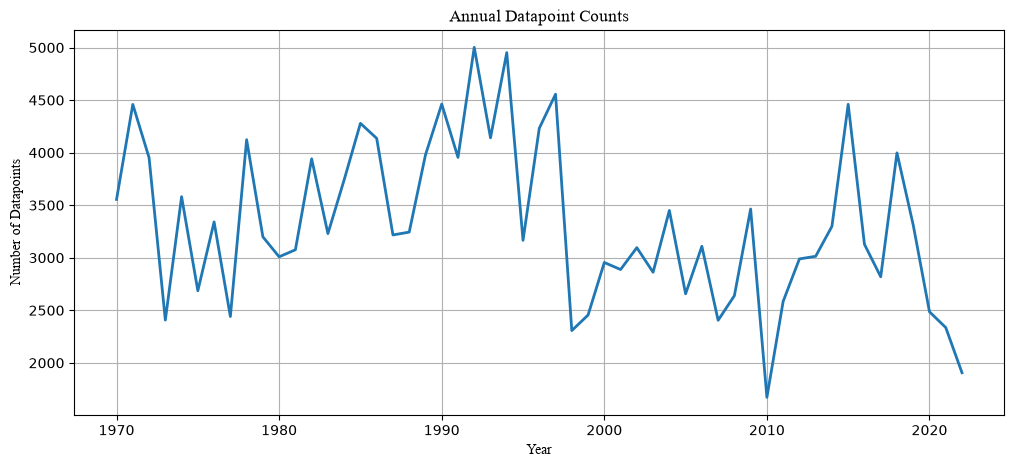

<Figure size 640x480 with 0 Axes>

In [125]:
### 3.10
# 按年分组
daily_n_DoY['YEAR'] = daily_n_DoY['DATE'].dt.year

# 统计数据点年总数
annual_n = daily_n_DoY.groupby('YEAR')['COUNT'].sum().reset_index()

# 绘图
plt.figure(figsize=(12,5))
plt.plot(annual_n.YEAR,annual_n.COUNT,linewidth=2)
plt.xlabel('Year',fontname='Times New Roman')
plt.ylabel('Number of Datapoints',fontname='Times New Roman')
plt.title('Annual Datapoint Counts',fontname='Times New Roman')
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_3_10.png",
            dpi = 300,
            bbox_inches="tight")

In [157]:
##### PS_4
### 4.1
# 加载pandas、numpy、plot和m'da'te's
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 读取数据
data4 = pd.read_csv(r'..\ESE5023\shenzhen-air-quality.csv')

# 将空白值替换为NaN
data4 = data4.replace(r'^\s*$', np.nan, regex=True)

# 转换时间序列
data4['date'] = pd.to_datetime(data4['date'], format='%Y/%m/%d')
data4 = data4.sort_values(by='date')

# 删除所有列名前后的空格
data4.columns = data4.columns.str.strip()

# 需要转换为数值类型的列名
cols = ['pm25', 'pm10', 'co', 'so2', 'o3', 'no2']

# 将这六列全部转换为数值类型
data4[cols] = data4[cols].apply(pd.to_numeric, errors='coerce')

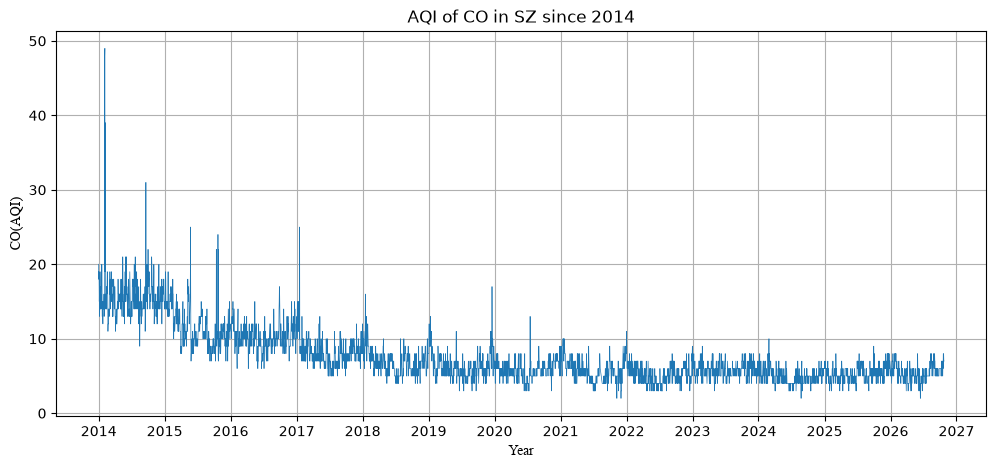

<Figure size 640x480 with 0 Axes>

In [158]:
### 4.2
# 删除co中的缺失值
data4 = data4.dropna(subset=['co'])

# 绘图
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(data4['date'], data4['co'], linewidth=0.5)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_xlabel('Year', fontname='Times New Roman')
ax.set_ylabel('CO(AQI)', fontname='Times New Roman')
ax.set_title('AQI of CO in SZ since 2014')
ax.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_4_2.png",
            dpi = 300,
            bbox_inches="tight")

count    4650.000000
mean        7.479785
std         3.618403
min         2.000000
25%         5.000000
50%         6.000000
75%         9.000000
max        49.000000
Name: co, dtype: float64
Median: 6.0
Skewness: 2.089452543038353


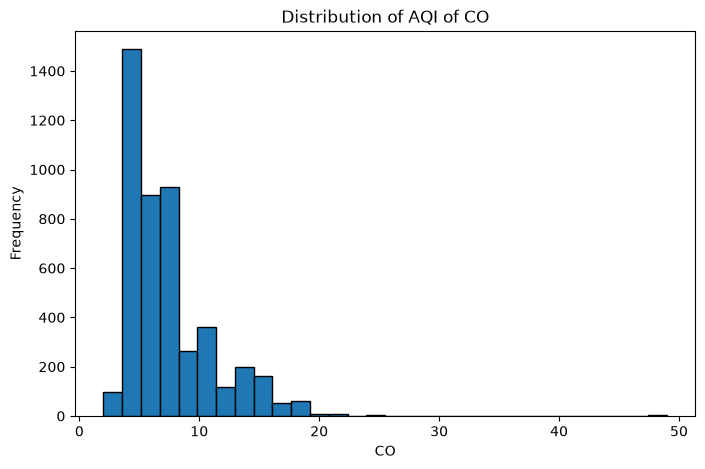

Lower bound: -1.0
Upper bound: 15.0
Potential outliers: 209
Outlier percentage: 4.494623655913978 %
date
2013    20.000000
2014    15.781768
2015    11.530220
2016    10.170799
2017     8.166205
2018     6.788462
2019     6.209366
2020     5.818681
2021     5.721127
2022     5.200000
2023     5.778082
2024     4.901099
2025     5.317680
2026     5.457912
Name: co, dtype: float64


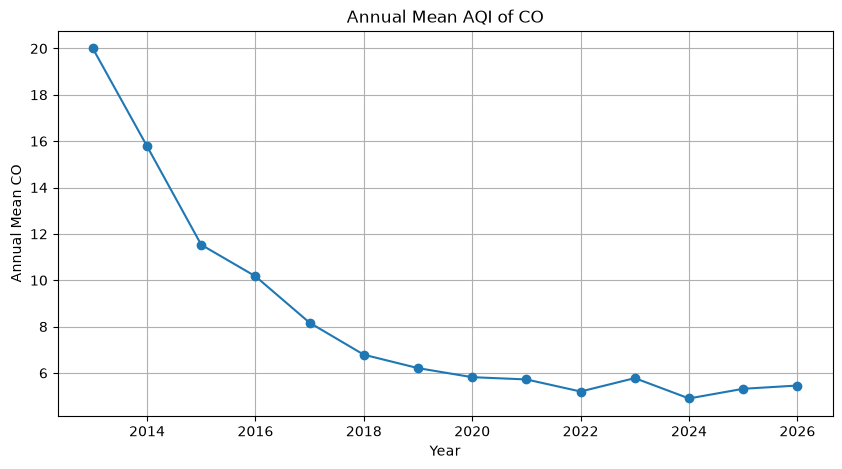

<Figure size 640x480 with 0 Axes>

In [161]:
### 4.3
co = data4['co']

# 1.描述性统计量
print(co.describe())
print('Median:', co.median())

# 2.偏度
print('Skewness:', co.skew())

# 3.分布形态
plt.figure(figsize=(8, 5))
plt.hist(co, bins=30, edgecolor='black')
plt.xlabel('CO')
plt.ylabel('Frequency')
plt.title('Distribution of AQI of CO')
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_4_3_3.png",
            dpi = 300,
            bbox_inches="tight")

# 4.异常值
Q1 = co.quantile(0.25)
Q3 = co.quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR
outliers = co[(co < lower) | (co > upper)]
print('Lower bound:', lower)
print('Upper bound:', upper)
print('Potential outliers:', len(outliers))
print('Outlier percentage:', len(outliers) / len(co) * 100, '%')

# 5.年际变化
annual_co = data4.groupby(data4['date'].dt.year)['co'].mean()
print(annual_co)
annual_co.plot(figsize=(10, 5), marker='o')
plt.xlabel('Year')
plt.ylabel('Annual Mean CO')
plt.title('Annual Mean AQI of CO')
plt.grid(True)
plt.show()

# 保存图片
plt.savefig(r"..\ESE5023\PS2_4_3_5.png",
            dpi = 300,
            bbox_inches="tight")